<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U3/Practica_1/AD_U3_Practica1_EsquivelJose.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


**Curso: Analitica de Datos**

**UNIDAD 3**

Jose Enrique Esquivel Torres

No. 23110182

Fecha de realizacion: 24/10/2026


---

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
#lectura del .csv con pandas
planet_df = pd.read_csv("/content/drive/MyDrive/T-Escuela_8/Analitica de Datos/Python/U3/Actividad_1/nasa_exoplanet_intelligence.csv")
planet_df

,planet_name,host_star,n_stars,n_planets,discovery_method,disc_year,disc_facility,orbital_period_days,planet_radius_earth,planet_mass_earth,...,ra,dec,controversial_flag,planet_type,habitable_zone_flag,multi_planet_system,is_recent_discovery,dist_category,star_type,orbital_period_cat
0,Kepler-1167 b,Kepler-1167,1,1,Transit,2016.0,Kepler,1.003934,1.710000,3.570000,...,298.302660,47.693965,0,Super-Earth,False,False,False,Far(500-2kpc),K-type,Short(1-10d)
1,Kepler-1740 b,Kepler-1740,1,1,Transit,2021.0,Kepler,8.172400,3.323214,11.000000,...,293.873663,38.922455,0,Mini-Neptune,False,False,True,Far(500-2kpc),G-type(Sun-like),Short(1-10d)
2,Kepler-1581 b,Kepler-1581,1,1,Transit,2016.0,Kepler,6.283855,0.800000,0.437000,...,287.371320,39.603623,0,Sub-Earth,False,False,False,Mid(100-500pc),F-type,Short(1-10d)
3,Kepler-644 b,Kepler-644,1,1,Transit,2016.0,Kepler,3.173917,3.150000,10.100000,...,295.475702,43.493112,0,Mini-Neptune,False,False,False,Far(500-2kpc),F-type,Short(1-10d)
4,Kepler-1752 b,Kepler-1752,1,1,Transit,2021.0,Kepler,56.358501,4.540605,18.700000,...,290.854140,51.222743,0,Neptune-like,False,False,True,Far(500-2kpc),G-type(Sun-like),Medium(10-100d)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6145,KMT-2024-BLG-1870L b,KMT-2024-BLG-1870L,1,1,Microlensing,2026.0,KMTNet,NaN,13.800000,336.898111,...,272.465333,-26.882889,0,Gas Giant,False,False,True,Distant(2k+pc),Unknown,Unknown
6146,TOI-2267 b,TOI-2267 A,2,3,Transit,2025.0,Transiting Exoplanet Survey Satellite (TESS),2.289090,1.000000,0.972000,...,65.061496,84.900824,0,Super-Earth,False,True,True,Nearby(<100pc),M-type(Red Dwarf),Short(1-10d)
6147,TOI-813 b,TOI-813,1,1,Transit,2020.0,Transiting Exoplanet Survey Satellite (TESS),83.891100,6.710000,36.400000,...,72.694010,-60.905461,0,Gas Giant,False,False,True,Mid(100-500pc),G-type(Sun-like),Medium(10-100d)
6148,LHS 1903 b,LHS 1903,1,4,Transit,2026.0,Transiting Exoplanet Survey Satellite (TESS),2.155510,1.382000,3.280000,...,107.865826,48.327933,0,Super-Earth,False,True,True,Nearby(<100pc),M-type(Red Dwarf),Short(1-10d)


In [ ]:
#Dimensiones del dataframe (columnas, registros)
planet_df.shape

(6150, 31)

In [ ]:
#Nombres de encabezados de columnas
planet_df.columns

Index(['planet_name', 'host_star', 'n_stars', 'n_planets', 'discovery_method',
       'disc_year', 'disc_facility', 'orbital_period_days',
       'planet_radius_earth', 'planet_mass_earth', 'equilibrium_temp_k',
       'orbital_eccentricity', 'semi_major_axis_au', 'star_temp_k',
       'star_radius_sun', 'star_mass_sun', 'star_age_gyr',
       'star_surface_gravity', 'star_metallicity', 'dist_from_earth_pc',
       'star_vmag', 'ra', 'dec', 'controversial_flag', 'planet_type',
       'habitable_zone_flag', 'multi_planet_system', 'is_recent_discovery',
       'dist_category', 'star_type', 'orbital_period_cat'],
      dtype='object')

In [ ]:
#Cantidad de filas que contiene el dataset
planet_df.index

RangeIndex(start=0, stop=6150, step=1)

In [ ]:
planet_df.dtypes

,0
planet_name,object
host_star,object
n_stars,int64
n_planets,int64
discovery_method,object
disc_year,float64
disc_facility,object
orbital_period_days,float64
planet_radius_earth,float64
planet_mass_earth,float64


In [ ]:
#Cantidad de valores unicos por cada una de las columnas
planet_df.nunique()

,0
planet_name,6150
host_star,4582
n_stars,4
n_planets,8
discovery_method,11
disc_year,34
disc_facility,73
orbital_period_days,5802
planet_radius_earth,2136
planet_mass_earth,2817


Podemos identificar que la columna de `planet_name` tiene 6150 registros como valores unicos lo que nos dice que no tienen ningun valor nulo y que ademas de eso todos son diferentes por lo cual la usamos como indice.

Hacemos la comprobacion de que todos los valores son unicos:

In [ ]:
print(planet_df["planet_name"].is_unique) #Contiene solo valores unicos
print(planet_df["planet_name"].isnull().sum()) #Suma de los calores unicos de la calumna

True
0


Como la columna `planet_name` es única y no contiene valores nulos, podemos definirla como el índice de nuestro DataFrame de la siguiente manera:

In [ ]:
planet_df = planet_df.set_index('planet_name')
planet_df.head()

,host_star,n_stars,n_planets,discovery_method,disc_year,disc_facility,orbital_period_days,planet_radius_earth,planet_mass_earth,equilibrium_temp_k,...,ra,dec,controversial_flag,planet_type,habitable_zone_flag,multi_planet_system,is_recent_discovery,dist_category,star_type,orbital_period_cat
planet_name,,,,,,,,,,,,,,,,,,,,,
Kepler-1167 b,Kepler-1167,1,1,Transit,2016.0,Kepler,1.003934,1.710000,3.570,1419.0,...,298.302660,47.693965,0,Super-Earth,False,False,False,Far(500-2kpc),K-type,Short(1-10d)
Kepler-1740 b,Kepler-1740,1,1,Transit,2021.0,Kepler,8.172400,3.323214,11.000,858.0,...,293.873663,38.922455,0,Mini-Neptune,False,False,True,Far(500-2kpc),G-type(Sun-like),Short(1-10d)
Kepler-1581 b,Kepler-1581,1,1,Transit,2016.0,Kepler,6.283855,0.800000,0.437,1108.0,...,287.371320,39.603623,0,Sub-Earth,False,False,False,Mid(100-500pc),F-type,Short(1-10d)
Kepler-644 b,Kepler-644,1,1,Transit,2016.0,Kepler,3.173917,3.150000,10.100,1655.0,...,295.475702,43.493112,0,Mini-Neptune,False,False,False,Far(500-2kpc),F-type,Short(1-10d)
Kepler-1752 b,Kepler-1752,1,1,Transit,2021.0,Kepler,56.358501,4.540605,18.700,419.0,...,290.854140,51.222743,0,Neptune-like,False,False,True,Far(500-2kpc),G-type(Sun-like),Medium(10-100d)


Analisamos de cuantos valores faltan en cada una de nuestras 31 columanas haciendo una suma y ademas calculamos el porcentaje equivalene con el total de datos que debe haber por cada fila:

In [ ]:
# Calcular cantidad de valores faltantes por columna
planet_df.isna().sum()

,0
host_star,0
n_stars,0
n_planets,0
discovery_method,0
disc_year,1
disc_facility,0
orbital_period_days,334
planet_radius_earth,50
planet_mass_earth,31
equilibrium_temp_k,1563


In [ ]:
# Calcular cantidad y porcentaje de valores nulos
valores_faltantes = planet_df.isna().sum()
porcentaje_faltantes = (planet_df.isna().sum() / len(planet_df)) * 100

# Consolidar en un DataFrame
resumen_faltantes = pd.DataFrame({
    'Cantidad Faltantes': valores_faltantes,
    'Porcentaje (%)': porcentaje_faltantes
})

# Ordenar de forma ascendente
resumen_faltantes_ordenado = resumen_faltantes.sort_values(by='Cantidad Faltantes', ascending=False)

# Mostrar el resultado
display(resumen_faltantes_ordenado)

,Cantidad Faltantes,Porcentaje (%)
equilibrium_temp_k,1563,25.414634
star_age_gyr,1311,21.317073
orbital_eccentricity,938,15.252033
star_metallicity,550,8.943089
orbital_period_days,334,5.430894
star_surface_gravity,318,5.170732
semi_major_axis_au,316,5.138211
star_radius_sun,314,5.105691
star_vmag,295,4.796748
star_temp_k,290,4.715447


### 1. Estadísticas Descriptivas (Medias y tendencia central)

Calculamos la media de todas las variables numéricas del dataset para entender sus valores promedio centrales.

In [ ]:
# Obtener la media de las variables numéricas principales
columnas_numericas = planet_df.select_dtypes(include=[np.number]).columns
medias = planet_df[columnas_numericas].mean()

# Crear un DataFrame para presentarlo de forma ordenada
resumen_estadistico = pd.DataFrame({
    'Media': medias,
    'Mediana': planet_df[columnas_numericas].median(),
    'Desviación Estándar': planet_df[columnas_numericas].std()
})

display(resumen_estadistico)

,Media,Mediana,Desviación Estándar
n_stars,1.103740,1.000000,3.430925e-01
n_planets,1.774309,1.000000,1.158362e+00
disc_year,2016.986339,2016.000000,4.964920e+00
orbital_period_days,73594.206576,11.125222,5.273718e+06
planet_radius_earth,5.841983,2.840000,5.436387e+00
planet_mass_earth,406.787994,9.270000,1.142866e+03
equilibrium_temp_k,912.895472,818.000000,4.642711e+02
orbital_eccentricity,0.079236,0.000000,1.528807e-01
semi_major_axis_au,15.718494,0.102015,3.490439e+02
star_temp_k,5398.163985,5546.000000,1.747460e+03


In [ ]:
# Configuración general de estilo para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

#### A. 3 Gráficos de Barras

/tmp/ipykernel_915/3413764677.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=metodos_top.values, y=metodos_top.index, palette='viridis')


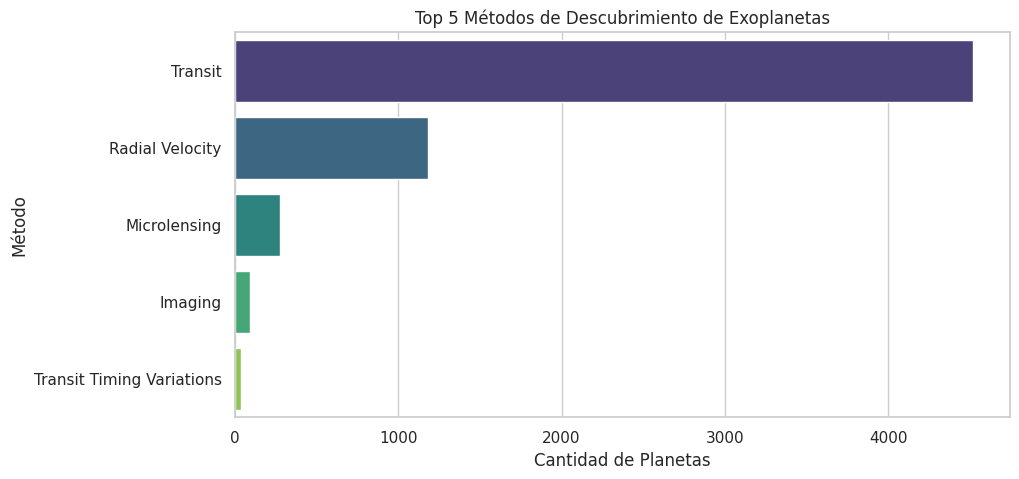

In [ ]:
# Gráfico de Barras 1: Cantidad de planetas por método de descubrimiento (Top 5)
plt.figure(figsize=(10, 5))
metodos_top = planet_df['discovery_method'].value_counts().head(5)
sns.barplot(x=metodos_top.values, y=metodos_top.index, palette='viridis')
plt.title('Top 5 Métodos de Descubrimiento de Exoplanetas')
plt.xlabel('Cantidad de Planetas')
plt.ylabel('Método')
plt.show()

/tmp/ipykernel_915/265167758.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tipos_planeta.index, y=tipos_planeta.values, palette='magma')


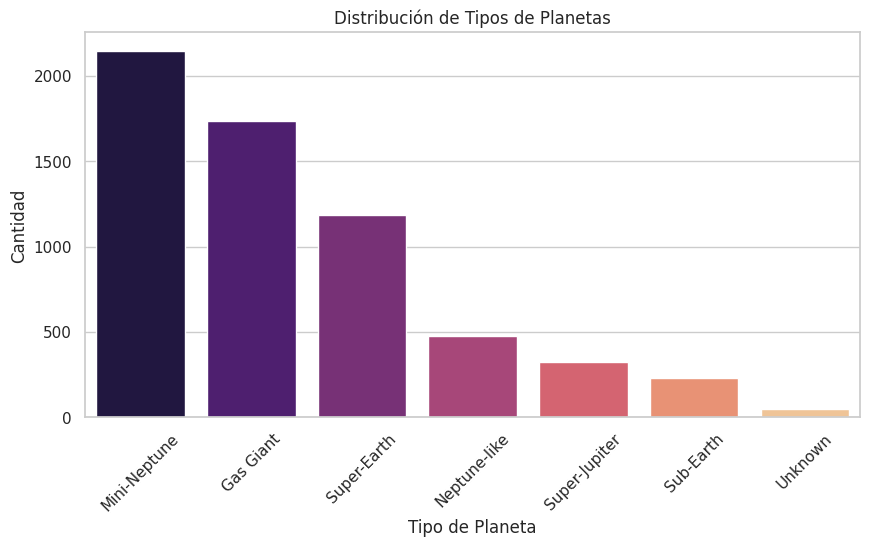

In [ ]:
# Gráfico de Barras 2: Tipos de planetas más comunes
plt.figure(figsize=(10, 5))
tipos_planeta = planet_df['planet_type'].value_counts()
sns.barplot(x=tipos_planeta.index, y=tipos_planeta.values, palette='magma')
plt.title('Distribución de Tipos de Planetas')
plt.xlabel('Tipo de Planeta')
plt.ylabel('Cantidad')
plt.xticks(rotation=45)
plt.show()

/tmp/ipykernel_915/1340188978.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=tipos_estrella.values, y=tipos_estrella.index, palette='coolwarm')


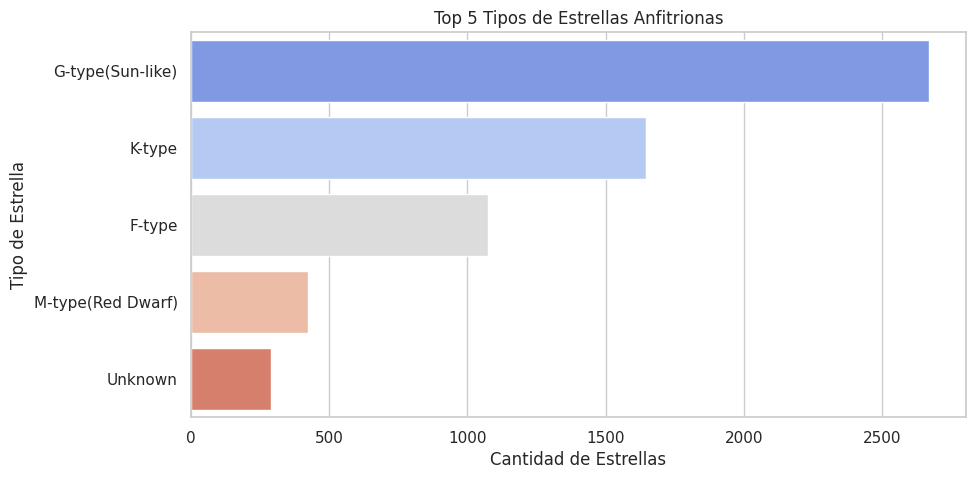

In [ ]:
# Gráfico de Barras 3: Tipos de estrella más comunes
plt.figure(figsize=(10, 5))
tipos_estrella = planet_df['star_type'].value_counts().head(5)
sns.barplot(x=tipos_estrella.values, y=tipos_estrella.index, palette='coolwarm')
plt.title('Top 5 Tipos de Estrellas Anfitrionas')
plt.xlabel('Cantidad de Estrellas')
plt.ylabel('Tipo de Estrella')
plt.show()

#### B. 1 Gráfico de Dispersión (Scatter Plot)

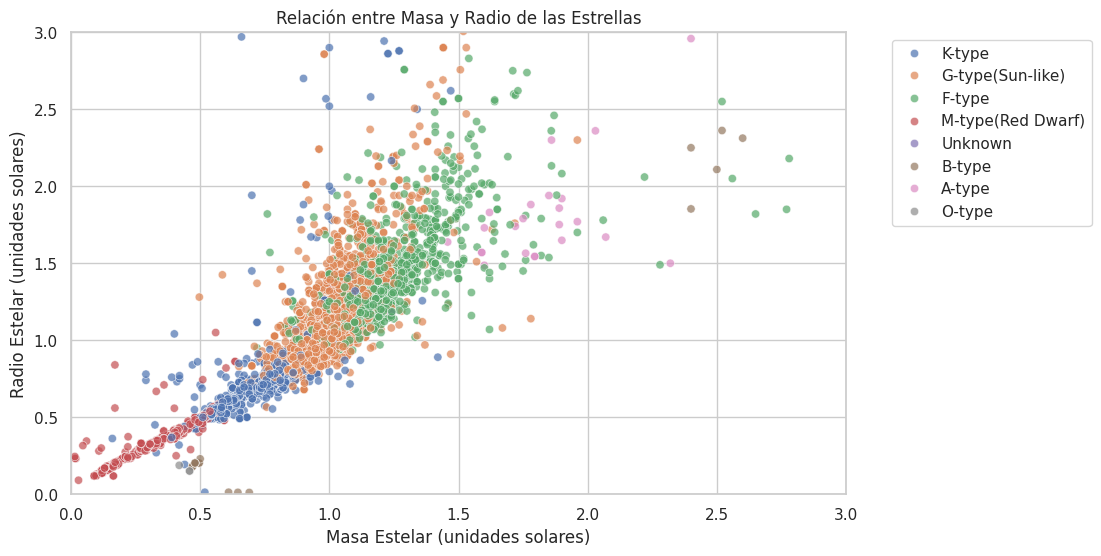

In [ ]:
# Relación entre la Masa de la estrella y el Radio de la estrella
plt.figure(figsize=(10, 6))
sns.scatterplot(data=planet_df, x='star_mass_sun', y='star_radius_sun', hue='star_type', alpha=0.7)
plt.title('Relación entre Masa y Radio de las Estrellas')
plt.xlabel('Masa Estelar (unidades solares)')
plt.ylabel('Radio Estelar (unidades solares)')
plt.xlim(0, 3) # Acotamos para evitar valores atípicos que distorsionen la escala
plt.ylim(0, 3)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

/tmp/ipykernel_915/3395800504.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=planet_df, x='planet_type', y='planet_mass_earth', palette='Set2')


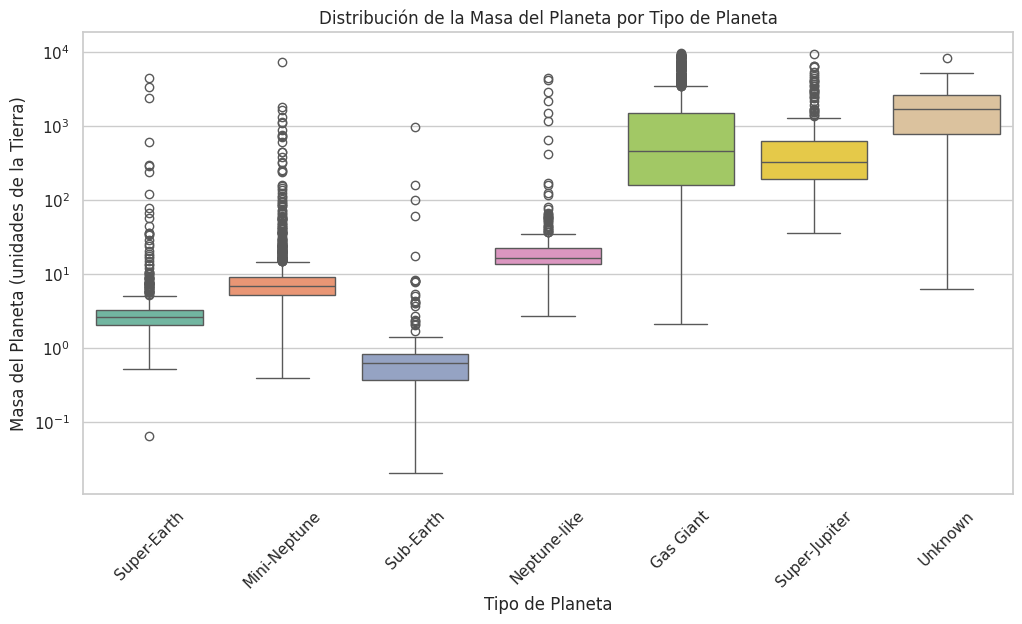

In [ ]:
# Gráfico de Caja 1: Distribución de la masa del planeta según su tipo
plt.figure(figsize=(12, 6))
sns.boxplot(data=planet_df, x='planet_type', y='planet_mass_earth', palette='Set2')
plt.title('Distribución de la Masa del Planeta por Tipo de Planeta')
plt.xlabel('Tipo de Planeta')
plt.ylabel('Masa del Planeta (unidades de la Tierra)')
plt.yscale('log') # Escala logarítmica debido a la amplia disparidad de masas
plt.xticks(rotation=45)
plt.show()

/tmp/ipykernel_915/2040214622.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=planet_df, x='star_type', y='star_temp_k', palette='pastel')


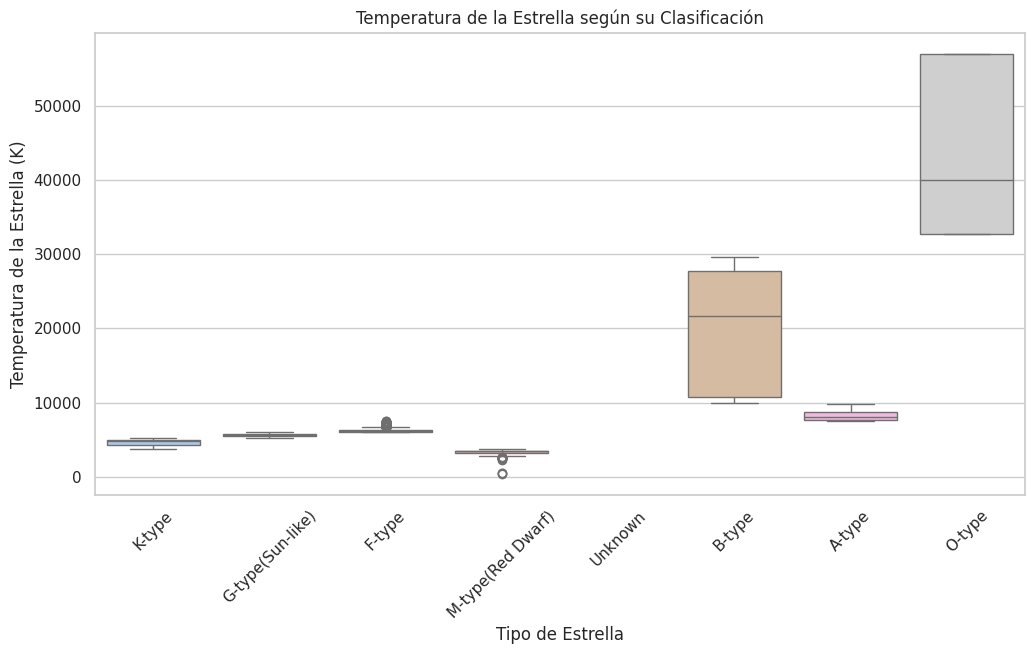

In [ ]:
# Gráfico de Caja 2: Temperatura de la estrella según el tipo de estrella
plt.figure(figsize=(12, 6))
sns.boxplot(data=planet_df, x='star_type', y='star_temp_k', palette='pastel')
plt.title('Temperatura de la Estrella según su Clasificación')
plt.xlabel('Tipo de Estrella')
plt.ylabel('Temperatura de la Estrella (K)')
plt.xticks(rotation=45)
plt.show()

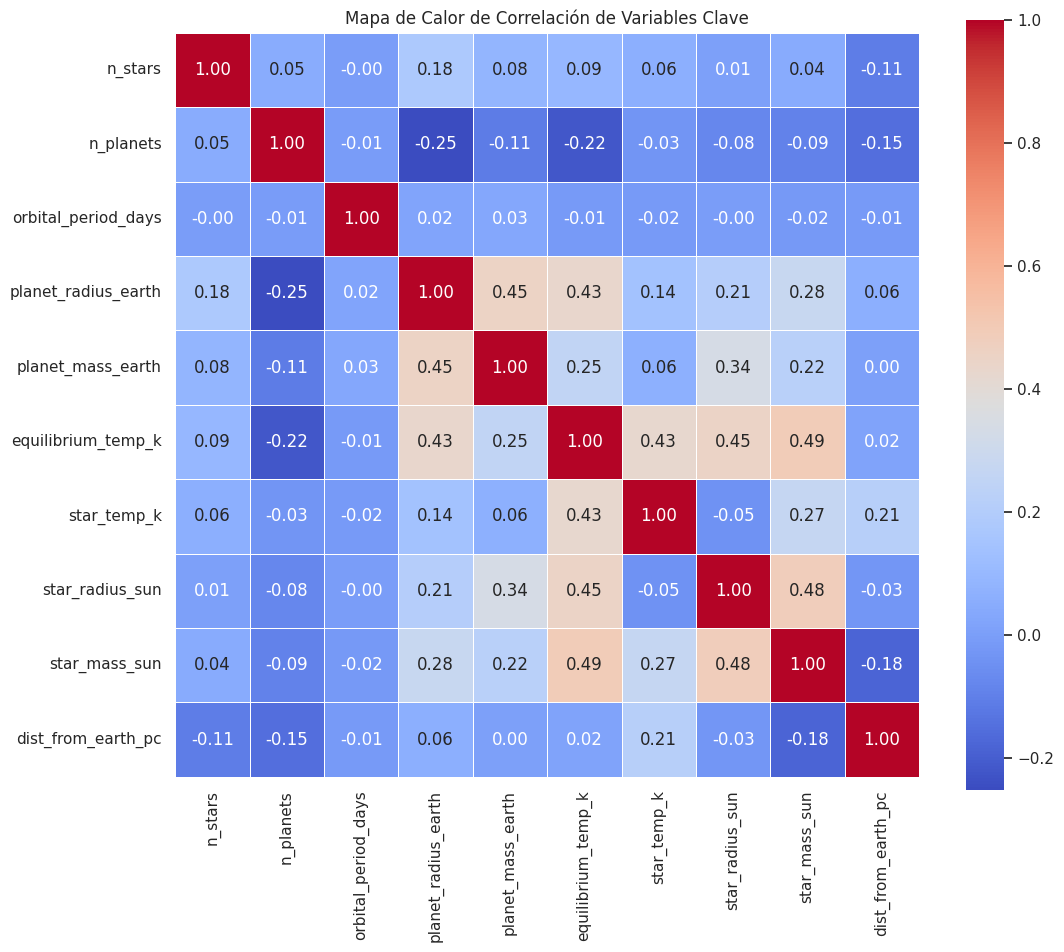

In [ ]:
# Selección de un subconjunto de variables numéricas relevantes para una visualización clara
columnas_interes = ['n_stars', 'n_planets', 'orbital_period_days',
                     'planet_radius_earth', 'planet_mass_earth', 'equilibrium_temp_k',
                     'star_temp_k', 'star_radius_sun', 'star_mass_sun', 'dist_from_earth_pc']

matriz_corr = planet_df[columnas_interes].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap='coolwarm', square=True, linewidths=0.5)
plt.title('Mapa de Calor de Correlación de Variables Clave')
plt.show()

### 3. Análisis de Sesgo (Skewness) de las Variables

El sesgo mide la simetría de la distribución de los datos:
* Un valor de **0** indica una distribución perfectamente simétrica.
* Un valor **positivo (> 0)** indica sesgo a la derecha (cola larga a la derecha, la mayoría de datos son pequeños).
* Un valor **negativo (< 0)** indica sesgo a la izquierda (cola larga a la izquierda, la mayoría de datos son grandes).

In [ ]:
# Calcular el sesgo (skewness) de todas las variables numéricas
sesgo_variables = planet_df[columnas_numericas].skew()

# Crear un DataFrame descriptivo
resumen_sesgo = pd.DataFrame({
    'Coeficiente de Sesgo': sesgo_variables
})

# Añadir interpretación del sesgo
def interpretar_sesgo(valor):
    if abs(valor) < 0.5:
        return 'Aproximadamente simétrica'
    elif valor >= 0.5 and valor < 1:
        return 'Sesgo positivo moderado'
    elif valor <= -0.5 and valor > -1:
        return 'Sesgo negativo moderado'
    elif valor >= 1:
        return 'Altamente sesgada positivamente (derecha)'
    else:
        return 'Altamente sesgada negativamente (izquierda)'

resumen_sesgo['Interpretación'] = resumen_sesgo['Coeficiente de Sesgo'].apply(interpretar_sesgo)
display(resumen_sesgo.sort_values(by='Coeficiente de Sesgo', ascending=False))

,Coeficiente de Sesgo,Interpretación
orbital_period_days,76.154523,Altamente sesgada positivamente (derecha)
semi_major_axis_au,39.396636,Altamente sesgada positivamente (derecha)
star_temp_k,15.083237,Altamente sesgada positivamente (derecha)
star_radius_sun,13.221139,Altamente sesgada positivamente (derecha)
controversial_flag,11.071496,Altamente sesgada positivamente (derecha)
star_mass_sun,6.149155,Altamente sesgada positivamente (derecha)
planet_mass_earth,4.385545,Altamente sesgada positivamente (derecha)
dist_from_earth_pc,3.995273,Altamente sesgada positivamente (derecha)
n_stars,3.495885,Altamente sesgada positivamente (derecha)
orbital_eccentricity,2.637990,Altamente sesgada positivamente (derecha)
